In [2]:
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
from imblearn import FunctionSampler
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC

DATASET = Path("Datasets/Processed/Dataset Dupilumab Baseline.xlsx - Anagrafica.csv")


def load_dataset():
    for root in (Path.cwd(), *Path.cwd().parents):
        if (root / DATASET).is_file():
            return pd.read_csv(root / DATASET)
    raise FileNotFoundError(DATASET)

class MultiColumnBinarizer(BaseEstimator, TransformerMixin):
    # BaseEstimator: provides parameter handling for sklearn Pipelines and GridSearch
    # TransformerMixin: automatically implements the fit_transform() method

    def __init__(self, min_frequency):
        self.min_frequency = min_frequency
        self.binarizers_ = {}
        self.col_names_ = []
        self.frequent_classes_ = {}


    def _parse_series(self, series):
        series = series.fillna("").astype(str) # Missing values become 0
        parsed = []
        for row in series:
            if not row.strip():
                parsed.append([])
            else:
                items = [
                    item.strip().lower()
                    for item in row.split(",")
                    if item.strip()
                ]
                parsed.append(list(set(items)))
        return parsed

    def _map_rare_to_other(self, lists, freq_set):
        # Maps infrequent or unseen categories into 'other'
        return [list({item if item in freq_set else "other" for item in sublist}) for sublist in lists]

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        self.col_names_ = list(X_df.columns)
        self.binarizers_ = {}
        self.frequent_classes_ = {}

        for col in self.col_names_:
            lists = self._parse_series(X_df[col])
            
            # Count occurrences in the training set and keep classes >= min_frequency
            all_items = [item for sublist in lists for item in sublist]
            counts = pd.Series(all_items).value_counts()
            freq_set = set(counts[counts >= self.min_frequency].index)
            self.frequent_classes_[col] = freq_set

            # Map rare classes to 'other' before fitting MultiLabelBinarizer
            mapped_lists = self._map_rare_to_other(lists, freq_set)
            all_classes = sorted(list(freq_set | {"other"}))

            mlb = MultiLabelBinarizer(classes=all_classes, sparse_output=False)
            mlb.fit(mapped_lists)
            self.binarizers_[col] = mlb

        return self
   

    def transform(self, X):
        X_df = pd.DataFrame(X, columns=self.col_names_)
        transformed_parts = []
        
        for col in self.col_names_:
            lists = self._parse_series(X_df[col])
            mapped_lists = self._map_rare_to_other(lists, self.frequent_classes_[col])
            transformed_parts.append(self.binarizers_[col].transform(mapped_lists))
            
        return np.hstack(transformed_parts)

    def get_feature_names_out(self, input_features=None):
        feature_names = []
        for col in self.col_names_:
            prefix = col.lower().replace(" ", "_")
            classes = self.binarizers_[col].classes_
            feature_names.extend([f"{prefix}_{c.replace(' ', '_')}" for c in classes])
        return np.array(feature_names)

def smotenc_resample(X, y, fattore, random_state):
    if fattore == 1:
        return X, y
    prefixes = tuple(col.lower().replace(" ", "_") + "_" for col in rbf_multi_categorical_cols)
    cat_idx = [i for i, col in enumerate(X.columns)
               if col in rbf_categorical_cols or col in rbf_ordinal_cols or col.startswith(prefixes)]
    return SMOTENC(
        categorical_features=cat_idx,
        sampling_strategy={label: round(n * fattore) for label, n in Counter(y).items()},
        k_neighbors=5,
        random_state=random_state,
    ).fit_resample(X, y)


In [4]:
# RBF SVC | set A
raw_rbf = load_dataset()

rbf_continuous_cols = [
    "Peso (kg)",
    "Altezza (cm)",
    "Neutrofili",
    "Linfociti",
    "Monociti",
    "Eosinofili",
    "Basofili",
    "IgE totali",
]

rbf_discrete_cols = [
    "Età",
    "Num Comorbidità",
    "Numero di pregressi interventi ESS",
    "N. allergeni positivi",
    "Giorni al mese di utilizzo spray",
    "ACT",
    "NPS",
    "NCS",
    "Dolore facciale",
    "Starnuti",
]

rbf_categorical_cols = [
    "Categoria Professione",
    "Sesso",
    "Biologico precedente (0 no, 1 sì)",
    "Familiarità Atopia",
    "OCS nell'ultimo anno",
    "Intolleranza ai FANS",
]

rbf_multi_categorical_cols = [
    "Comorbidità",
    "Quali allergeni positivi",
]

rbf_ordinal_cols = [
    "Fumo Baseline (0=no, 1=ex, 2=si)",
]

rbf_numeric = rbf_continuous_cols + rbf_discrete_cols + rbf_ordinal_cols
rbf_features = rbf_numeric + rbf_categorical_cols + rbf_multi_categorical_cols
X_rbf = raw_rbf.loc[:, rbf_features].copy()
y_rbf = raw_rbf["TARGET"].astype(int)

for col in rbf_numeric:
    values = X_rbf[col].astype("string").str.strip()
    european = values.str.contains(",", regex=False, na=False)
    values = values.mask(european, values.str.replace(".", "", regex=False).str.replace(",", ".", regex=False))
    X_rbf[col] = pd.to_numeric(values, errors="coerce").astype(float)

rbf_pre = ColumnTransformer([
    ("num_cont", make_pipeline(SimpleImputer(strategy="mean"), StandardScaler()), rbf_continuous_cols),
    ("num_discr", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), rbf_discrete_cols),
    ("cat", SimpleImputer(strategy="most_frequent"), rbf_categorical_cols),
    ("multi_cat", MultiColumnBinarizer(min_frequency=2), rbf_multi_categorical_cols),
    ("ord", make_pipeline(SimpleImputer(strategy="most_frequent"), StandardScaler()), rbf_ordinal_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")

rbf_post = ColumnTransformer([
    ("cat", OneHotEncoder(sparse_output=False, drop="if_binary", handle_unknown="ignore"), rbf_categorical_cols),
], remainder="passthrough")

# Sostituisci None con i valori selezionati nella run del test.
rbf_model = SVC(
    kernel="rbf",
    C=1,
    gamma="scale",
    class_weight="balanced",
)
rbf_smotenc = FunctionSampler(
    func=smotenc_resample,
    validate=False,
    kw_args={
        "fattore": 1,  # 1.0 disattiva il ricampionamento.
        "random_state": 45,  # Inserisci il seed SMOTENC per riprodurre il fit.
    },
)
if rbf_model.C is None or rbf_model.gamma is None or rbf_smotenc.kw_args["fattore"] is None:
    raise ValueError("Compila C, gamma e il fattore SMOTENC prima del fit di RBF SVC.")

rbf_pipeline = ImbPipeline([
    ("pre", rbf_pre),
    ("smotenc", rbf_smotenc),
    ("post", rbf_post),
    ("model", rbf_model),
])
rbf_pipeline.fit(X_rbf, y_rbf)


,steps,"[('pre', ...), ('smotenc', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](27,)","['Peso (kg)','Altezza (cm)','Neutrofili',...,'Intolleranza ai FANS', 'Comorbidità','Quali allergeni positivi']"
n_features_in_,int,27
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_cont', ...), ('num_discr', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'


## EXPLAINABILITY

In [5]:
# ============================================================
# EXPLAINABILITY - RBF SVC | COMMON SETUP
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.inspection import (
    permutation_importance,
    PartialDependenceDisplay
)

# Fitted pipeline
best_pipeline = rbf_pipeline

pre = best_pipeline.named_steps["pre"]
post = best_pipeline.named_steps["post"]
model = best_pipeline.named_steps["model"]

# Original feature space
X_explain = X_rbf.copy()
y_explain = y_rbf.copy()

# Apply fitted preprocessing steps (without SMOTENC)
X_pre = pre.transform(X_explain)
X_transformed = post.transform(X_pre)

# Feature names after preprocessing and encoding
feature_names = post.get_feature_names_out()

X_transformed_df = pd.DataFrame(
    X_transformed,
    columns=feature_names,
    index=X_explain.index
).astype(float)

print("Original features:", X_explain.shape[1])
print("Transformed features:", X_transformed_df.shape[1])
print("Samples:", len(X_explain))
print("Classes:", model.classes_)

d:\ADSP\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Original features: 27
Transformed features: 60
Samples: 112
Classes: [0 1]


,Feature,Importance,Std
2,Neutrofili,0.017935,0.005984
12,Giorni al mese di utilizzo spray,0.015016,0.006791
0,Peso (kg),0.013274,0.009133
14,NPS,0.010210,0.005178
16,Dolore facciale,0.008710,0.003948
1,Altezza (cm),0.008548,0.002934
7,IgE totali,0.008500,0.004442
26,Quali allergeni positivi,0.008355,0.004373
17,Starnuti,0.007403,0.003278
19,Categoria Professione,0.006790,0.005155


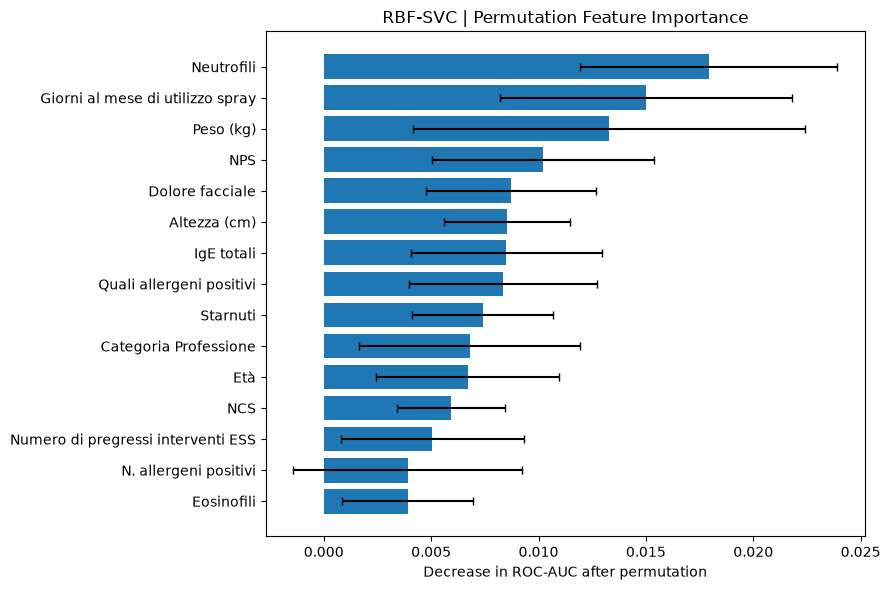

In [6]:
# ============================================================
# PERMUTATION FEATURE IMPORTANCE
# ============================================================

permutation = permutation_importance(
    estimator=best_pipeline,
    X=X_explain,
    y=y_explain,
    scoring="roc_auc",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "Feature": X_explain.columns,
    "Importance": permutation.importances_mean,
    "Std": permutation.importances_std
}).sort_values("Importance", ascending=False)

display(perm_df)

# Plot top 15
top_perm = perm_df.head(15).sort_values("Importance")

plt.figure(figsize=(9, 6))

plt.barh(
    top_perm["Feature"],
    top_perm["Importance"],
    xerr=top_perm["Std"],
    capsize=3
)

plt.xlabel("Decrease in ROC-AUC after permutation")
plt.title("RBF-SVC | Permutation Feature Importance")
plt.tight_layout()
plt.show()

100%|██████████| 15/15 [00:02<00:00,  5.98it/s]


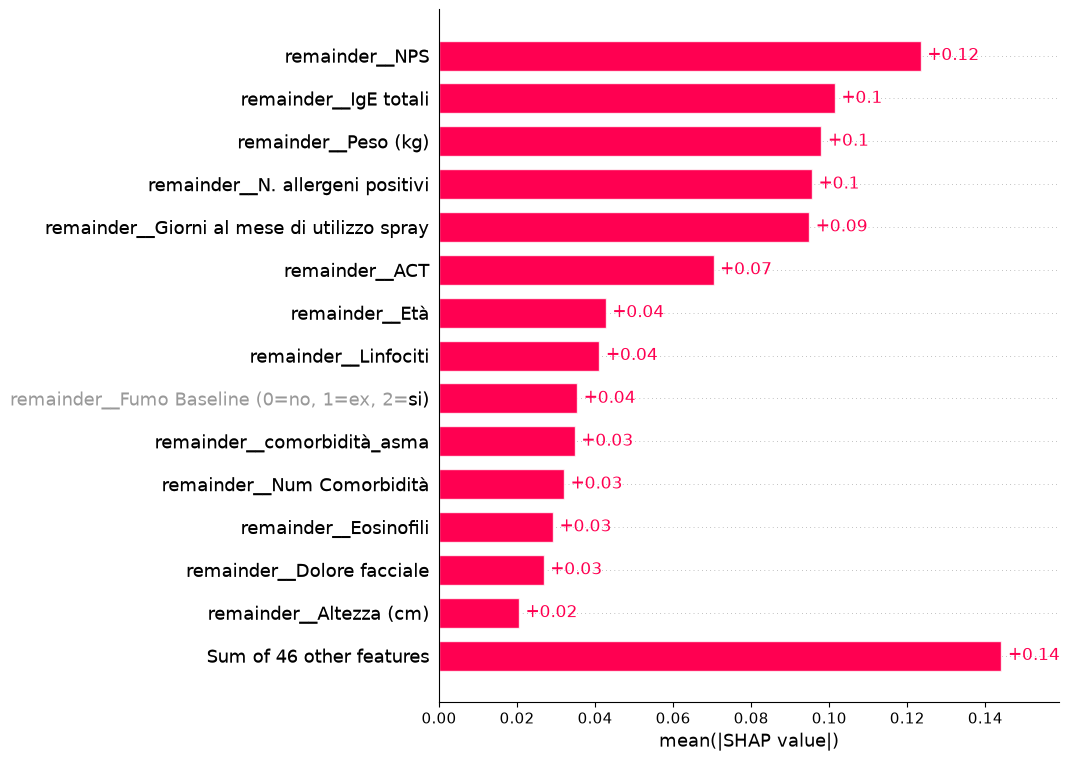

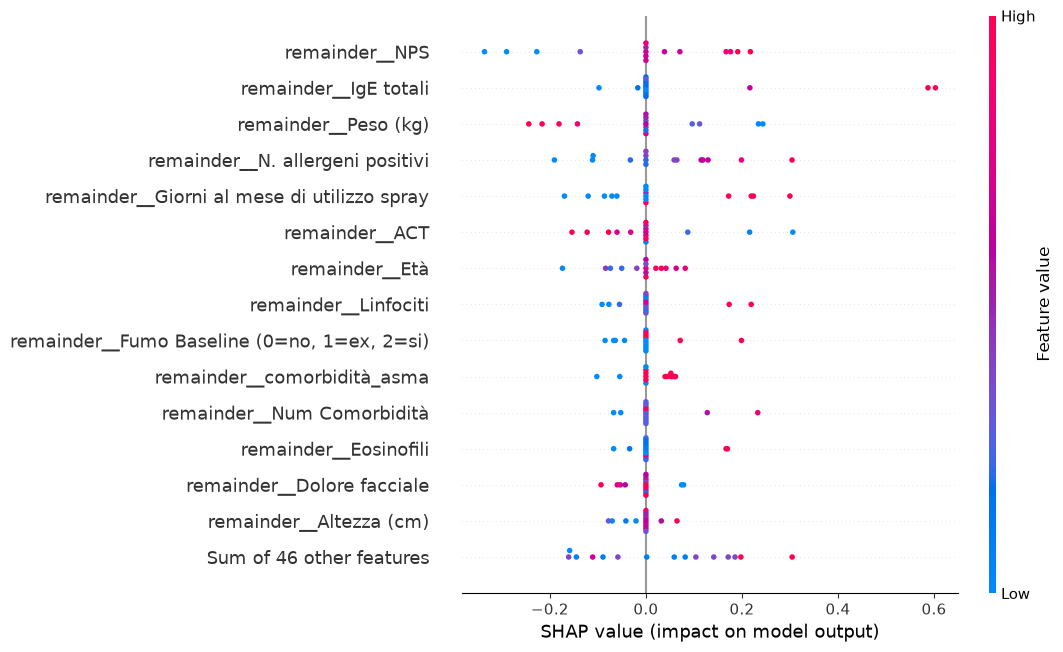

In [7]:
# ============================================================
# SHAP - GLOBAL EXPLAINABILITY
# ============================================================

# Representative background from the training feature space
background = shap.sample(
    X_transformed_df,
    min(30, len(X_transformed_df)),
    random_state=42
)

# Select patients to explain
X_shap = shap.sample(
    X_transformed_df,
    min(15, len(X_transformed_df)),
    random_state=123
)

# SHAP explainer for non-linear SVC
explainer = shap.KernelExplainer(
    model.decision_function,
    background
)

shap_values = explainer.shap_values(
    X_shap,
    nsamples=200
)

sv = shap.Explanation(
    values=np.asarray(shap_values),
    base_values=np.repeat(
        explainer.expected_value,
        len(X_shap)
    ),
    data=X_shap.to_numpy(),
    feature_names=list(feature_names)
)

# Global feature importance
shap.plots.bar(
    sv,
    max_display=15
)

# Global beeswarm
shap.plots.beeswarm(
    sv,
    max_display=15
)

Patient index: 94
True label: 0
Predicted class: 0
Decision score: -0.3077368133033002


d:\ADSP\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
d:\ADSP\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(


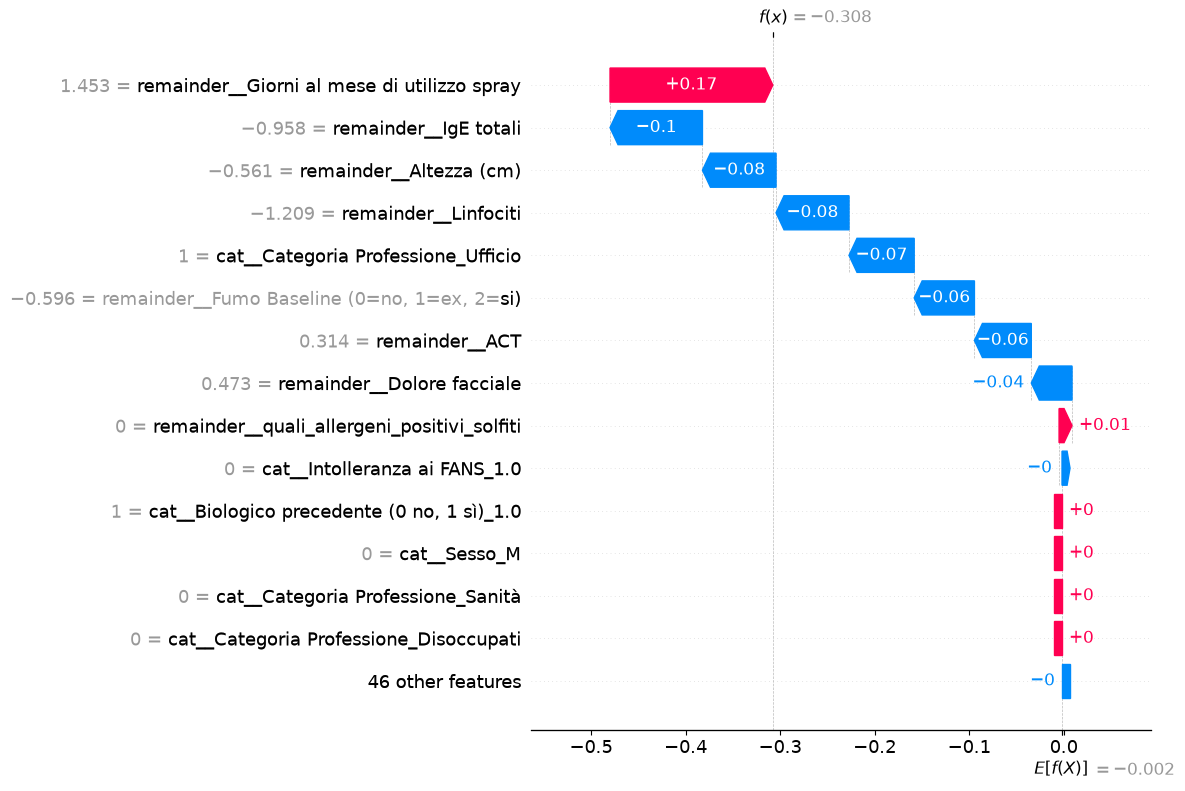

In [8]:
# ============================================================
# SHAP - LOCAL EXPLAINABILITY
# ============================================================

patient_idx = 0

print("Patient index:", X_shap.index[patient_idx])
print(
    "True label:",
    y_explain.loc[X_shap.index[patient_idx]]
)
print(
    "Predicted class:",
    model.predict(
        X_shap.iloc[[patient_idx]]
    )[0]
)
print(
    "Decision score:",
    model.decision_function(
        X_shap.iloc[[patient_idx]]
    )[0]
)

shap.plots.waterfall(
    sv[patient_idx],
    max_display=15
)

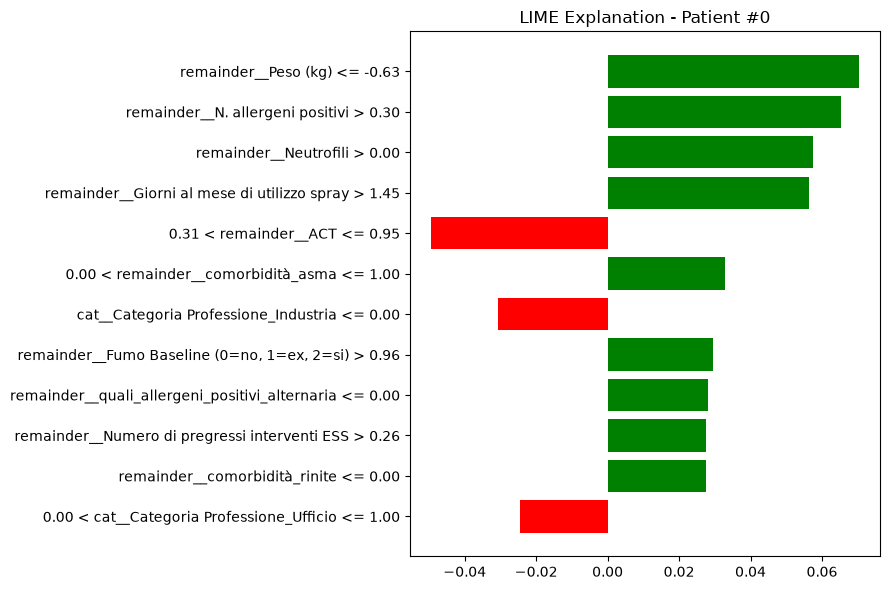

In [9]:
# ============================================================
# LIME - LOCAL EXPLAINABILITY
# ============================================================

import lime.lime_tabular
from scipy.special import expit

# LIME expects a two-column probability-like output.
# These are NOT calibrated probabilities.
def lime_predict_fn(X):
    scores = model.decision_function(
        np.asarray(X, dtype=float)
    )
    p1 = expit(scores)

    return np.column_stack([1 - p1, p1])


lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_transformed_df.to_numpy(),
    feature_names=list(feature_names),
    class_names=[
        "No eosinofilia",
        "Eosinofilia"
    ],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

# Explain one patient
patient_idx = 0

exp = lime_explainer.explain_instance(
    data_row=X_transformed_df.iloc[patient_idx].to_numpy(),
    predict_fn=lime_predict_fn,
    num_features=12,
    num_samples=3000
)

fig = exp.as_pyplot_figure()
fig.set_size_inches(9, 6)

plt.title(
    f"LIME Explanation - Patient #{patient_idx}"
)

plt.tight_layout()
plt.show()

Features selected: ['remainder__Neutrofili', 'remainder__Giorni al mese di utilizzo spray', 'remainder__Peso (kg)', 'remainder__NPS']


d:\ADSP\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
d:\ADSP\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
d:\ADSP\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
d:\ADSP\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but SVC was fitted without feature names
  warnings.warn(
d:\ADSP\2026-P8-LINKS_ADSP-Dupilumab_Eosinophilia_Early_Prediction\.venv\Lib\site-packages\sklearn\utils\validation.py:2823: UserWar

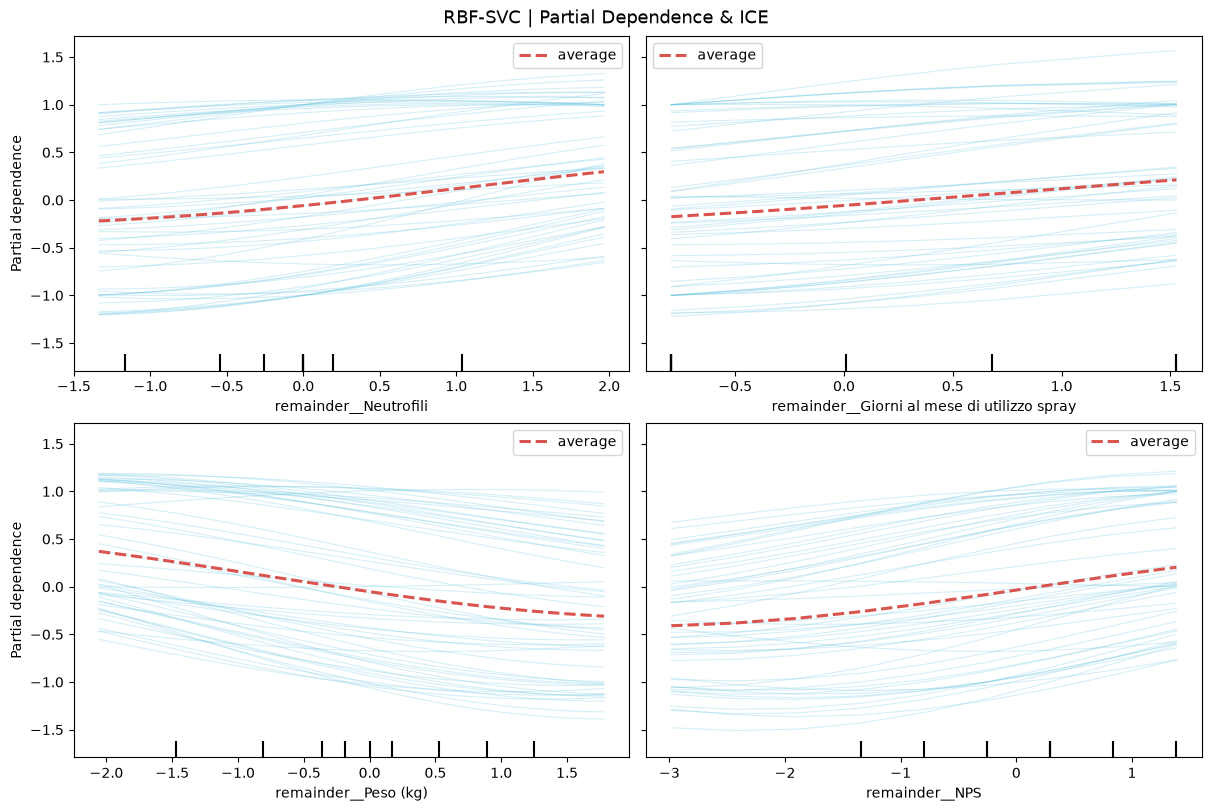

In [10]:
# ============================================================
# PARTIAL DEPENDENCE & ICE
# ============================================================

# Select numeric features from permutation importance
numeric_features = (
    rbf_continuous_cols
    + rbf_discrete_cols
    + rbf_ordinal_cols
)

top_numeric = [
    col for col in perm_df["Feature"]
    if col in numeric_features
][:4]

# Map original names to transformed feature names
features_to_plot = []

for col in top_numeric:
    matches = [
        name for name in X_transformed_df.columns
        if name == col or name.endswith("__" + col)
    ]

    if len(matches) == 1:
        features_to_plot.append(matches[0])

print("Features selected:", features_to_plot)

if not features_to_plot:
    raise ValueError("No matching numeric features found.")

fig, ax = plt.subplots(
    figsize=(12, 8),
    layout="constrained"
)

PartialDependenceDisplay.from_estimator(
    estimator=model,
    X=X_transformed_df,
    features=features_to_plot,
    kind="both",
    response_method="decision_function",
    subsample=50,
    n_cols=2,
    grid_resolution=30,
    random_state=42,
    ax=ax,
    ice_lines_kw={
        "color": "#5bc0de",
        "alpha": 0.25,
        "linewidth": 0.8
    },
    pd_line_kw={
        "color": "#d9534f",
        "linewidth": 2.2
    }
)

fig.suptitle(
    "RBF-SVC | Partial Dependence & ICE",
    fontsize=13
)

plt.show()